# External credit dataset validation — German Credit (OpenML credit-g)

This notebook provides the independent dataset experiment requested by Reviewer 1. It downloads the public **German Credit** dataset (OpenML data ID 31; 1,000 borrowers) when run with internet access. The protected-group variable is inferred from the dataset's `personal_status` coding; this is an imperfect proxy, which must be disclosed. Unlike the original Taiwan credit-card dataset, German Credit has a different feature space and outcome definition. Model fitting and fairness calibration are performed entirely within this dataset.

**Important:** This notebook has been syntax-checked, but has **not been executed** against OpenML in this environment. Do not report results until it runs successfully and the outputs are inspected.


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score
from scipy.ndimage import gaussian_filter1d
from scipy.special import logsumexp
from scipy.optimize import brentq
OUT=Path("german_credit_external_outputs");OUT.mkdir(exist_ok=True)
SEED=42
data=fetch_openml(data_id=31,as_frame=True,parser="auto")
df=data.frame.copy()
print("Dataset:",df.shape, "columns:",df.columns.tolist())
display(df.head())


Dataset: (1000, 21) columns: ['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker', 'class']


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


## Group labels and outcome

In [2]:
assert "personal_status" in df.columns
print("Personal status values:",df.personal_status.value_counts())
# OpenML credit-g commonly uses male div/sep, female div/dep/mar, male single,
# male mar/wid, female single. Support A91–A95 UCI codes as an alternative.
def infer_sex(v):
    x=str(v).lower().replace(" ","")
    if x in ("a91","a93","a94") or x.startswith("male"):return 0
    if x in ("a92","a95") or x.startswith("female"):return 1
    raise ValueError(f"Unknown personal_status code: {v}")
g=df.personal_status.map(infer_sex).to_numpy()
target_name=data.target.name if getattr(data.target,"name",None) in df.columns else "class"
y=(df[target_name].astype(str).str.lower()=="good").astype(int).to_numpy()
assert len(np.unique(y))==2
X=df.drop(columns=[target_name,"personal_status"])
print("Group 0 male, group 1 female:",np.bincount(g),"Good credit:",y.mean())


Personal status values: personal_status
male single           548
female div/dep/mar    310
male mar/wid           92
male div/sep           50
Name: count, dtype: int64
Group 0 male, group 1 female: [690 310] Good credit: 0.7


## Strict train / calibration / test protocol

In [3]:
ids=np.arange(len(y))
joint=np.array([f"{yy}_{gg}" for yy,gg in zip(y,g)])
train_ids,rest_ids=train_test_split(ids,test_size=.4,random_state=SEED,stratify=joint)
cal_ids,test_ids=train_test_split(rest_ids,test_size=.5,random_state=SEED,stratify=joint[rest_ids])
categorical=X.select_dtypes(exclude=np.number).columns.tolist()
numeric=[col for col in X.columns if col not in categorical]
prep=ColumnTransformer([
 ("categorical",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                           ("encode",OneHotEncoder(handle_unknown="ignore"))]),categorical),
 ("numeric",Pipeline([("impute",SimpleImputer(strategy="median"))]),numeric)])
models={"Logistic regression":LogisticRegression(max_iter=2000,random_state=SEED),
        "Random forest":RandomForestClassifier(n_estimators=300,min_samples_leaf=3,random_state=SEED)}
try:
 from xgboost import XGBClassifier
 models["XGBoost"]=XGBClassifier(n_estimators=350,max_depth=3,learning_rate=.045,
  subsample=.85,colsample_bytree=.9,eval_metric="logloss",tree_method="hist",
  random_state=SEED,n_jobs=4)
except ImportError: print("Install xgboost to include XGBoost benchmark")
def evaluate(z,labels,groups,tau):
 pred=(z>=tau).astype(int)
 rates=[];tpr=[];fpr=[]
 for k in (0,1):
  m=groups==k
  rates.append(pred[m].mean())
  tpr.append(pred[m & (labels==1)].mean())
  fpr.append(pred[m & (labels==0)].mean())
 return {"accuracy":accuracy_score(labels,pred),"balanced_accuracy":balanced_accuracy_score(labels,pred),
         "roc_auc":roc_auc_score(labels,z),"pr_auc":average_precision_score(labels,z),
         "abs_dp":abs(rates[0]-rates[1]),"abs_eo":abs(tpr[0]-tpr[1]),
         "abs_fpr":abs(fpr[0]-fpr[1])}
model_results=[];score_cache={}
for name,estimator in models.items():
 pipe=Pipeline([("prep",prep),("model",estimator)])
 pipe.fit(X.iloc[train_ids],y[train_ids])
 sc=pipe.predict_proba(X.iloc[cal_ids])[:,1]
 st=pipe.predict_proba(X.iloc[test_ids])[:,1]
 thresholds=np.linspace(.05,.95,901)
 scores=[balanced_accuracy_score(y[cal_ids],sc>=t) for t in thresholds]
 tau=float(thresholds[np.argmax(scores)])
 model_results.append({"model":name,"threshold":tau,**evaluate(st,y[test_ids],g[test_ids],tau)})
 score_cache[name]=(sc,st,tau)
baseline=pd.DataFrame(model_results)
display(baseline)
baseline.to_csv(OUT/"external_classifier_benchmarks.csv",index=False)


/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model,threshold,accuracy,balanced_accuracy,roc_auc,pr_auc,abs_dp,abs_eo,abs_fpr
0,Logistic regression,0.717,0.685,0.689286,0.758333,0.887041,0.022674,0.10,0.043062
1,Random forest,0.703,0.665,0.675000,0.735000,0.873706,0.018467,0.00,0.028708
2,XGBoost,0.649,0.685,0.655952,0.740000,0.864612,0.008649,0.03,0.011962


## Calibrate stationary coupled densities and transport untouched test scores

In [4]:
base_name="XGBoost" if "XGBoost" in score_cache else "Logistic regression"
sc,st,tau=score_cache[base_name]
gc=g[cal_ids];gt=g[test_ids];yt=y[test_ids]
D=.001;N=400;edges=np.linspace(0,1,N+1);h=1/N;s=(edges[:-1]+edges[1:])/2
def dens(z):
 counts,_=np.histogram(z,bins=edges)
 rr=gaussian_filter1d(counts.astype(float),sigma=2,mode="reflect")+1e-7
 return rr/(h*rr.sum())
initial=np.stack([dens(sc[gc==k]) for k in (0,1)])
fraction=np.clip((edges[1:]-np.maximum(edges[:-1],tau))/h,0,1)
def gap(rr):return h*np.dot(fraction,rr[0]-rr[1])
def stationary(lam,delta):
 arr=[]
 for k in (0,1):
  sign=1 if k==0 else -1
  w=np.log(initial[k])-lam*sign*delta*s/D
  w-=logsumexp(w)
  arr.append(np.exp(w)/h)
 return np.stack(arr)
def fit_stationary(lam):
 if lam==0:return initial.copy()
 delta=brentq(lambda d:gap(stationary(lam,d))-d,-1,1)
 return stationary(lam,delta)
def map_scores(z,old,new):
 u=np.interp(z,edges,np.r_[0,np.cumsum(old)*h])
 cdf=np.r_[0,np.cumsum(new)*h]
 v,idx=np.unique(cdf,return_index=True)
 return np.interp(u,v,edges[idx])
rows=[]
for lam in [0,.0025,.005,.01,.02,.05,.1,.2]:
 rr=fit_stationary(lam)
 adjusted=st.copy()
 for k in (0,1):
  mask=gt==k
  adjusted[mask]=map_scores(st[mask],initial[k],rr[k])
 rows.append({"lambda":lam,"calibration_density_gap":gap(rr),
              **evaluate(adjusted,yt,gt,tau)})
result=pd.DataFrame(rows)
display(result)
result.to_csv(OUT/"external_pde_fairness.csv",index=False)


,lambda,calibration_density_gap,accuracy,balanced_accuracy,roc_auc,pr_auc,abs_dp,abs_eo,abs_fpr
0,0.0000,0.231482,0.685,0.655952,0.740000,0.864612,0.008649,0.030,0.011962
1,0.0025,0.144434,0.680,0.647619,0.736607,0.863057,0.077606,0.135,0.033493
2,0.0050,0.104551,0.665,0.636905,0.732143,0.863107,0.169472,0.165,0.248804
3,0.0100,0.067244,0.675,0.658333,0.727798,0.861824,0.198457,0.175,0.327751
4,0.0200,0.039209,0.675,0.658333,0.725536,0.860838,0.198457,0.175,0.327751
5,0.0500,0.017414,0.675,0.658333,0.724286,0.860392,0.198457,0.175,0.327751
6,0.1000,0.009039,0.675,0.658333,0.724583,0.860559,0.198457,0.175,0.327751
7,0.2000,0.004607,0.675,0.658333,0.723929,0.860116,0.198457,0.175,0.327751


## External-validation figures and reproducibility record

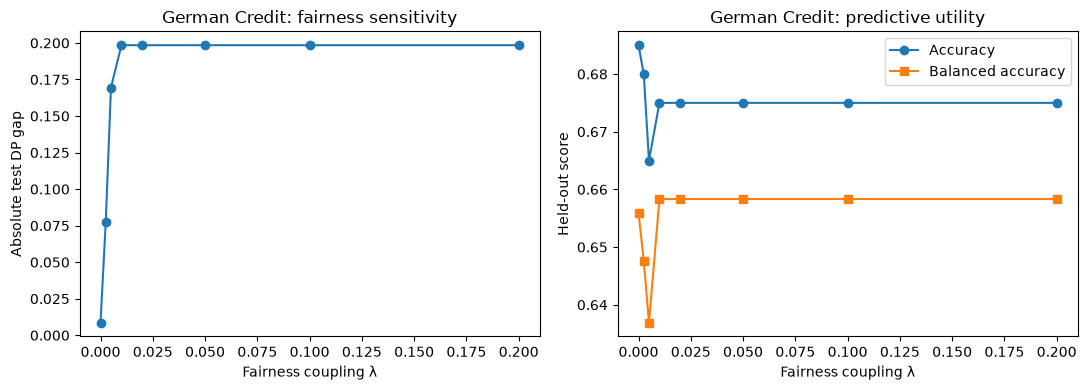

Output directory: /Users/olusolaolabanjo/Desktop/pde-credit-scoring/exval/german_credit_external_outputs


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(result["lambda"],result["abs_dp"],"o-")
axes[0].set(xlabel="Fairness coupling λ",ylabel="Absolute test DP gap",title="German Credit: fairness sensitivity")
axes[1].plot(result["lambda"],result["accuracy"],"o-",label="Accuracy")
axes[1].plot(result["lambda"],result["balanced_accuracy"],"s-",label="Balanced accuracy")
axes[1].set(xlabel="Fairness coupling λ",ylabel="Held-out score",title="German Credit: predictive utility")
axes[1].legend()
plt.tight_layout();fig.savefig(OUT/"external_fairness_accuracy.png",dpi=200);plt.show()
(OUT/"experiment_settings.json").write_text(json.dumps({
 "dataset":"OpenML credit-g","openml_data_id":31,"seed":SEED,
 "train_n":len(train_ids),"calibration_n":len(cal_ids),"test_n":len(test_ids),
 "protected_group":"personal_status derived sex proxy","target":"good credit",
 "baseline_model":base_name,"diffusion":D,"grid_cells":N,
 "threshold":tau,"lambda_values":result["lambda"].tolist()},indent=2))
print("Output directory:",OUT.resolve())
